# Lab 4

Import bibliotek

In [55]:
import sys
import numpy as np
import pandas as pd
import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
import sklearn

Weryfikacja pakietow

In [56]:
print('Python:       ' + sys.version.split()[0])
print('NumPy:        ' + np.__version__)
print('pandas:       ' + pd.__version__)
print('Matplotlib:   ' + mp.__version__)
print('Seaborn:      ' + sns.__version__)
print('Scikit-learn: ' + sklearn.__version__)

Python:       3.14.0
NumPy:        2.2.6
pandas:       2.3.3
Matplotlib:   3.11.2
Seaborn:      0.13.2
Scikit-learn: 1.7.2


Wczytanie danych

Uwaga od wykladowcy: w zbiorach moga byc brakujace wartosci.

In [57]:
titanic = pd.read_csv('titanic.csv')
titanic.info()
titanic.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home_dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home_dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [58]:
titanic.isna().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home_dest     564
dtype: int64

In [59]:
heart = pd.read_csv('heart.csv')
heart.info()
heart.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [60]:
print(heart.isna().sum().sum())
print((heart[['RestingBP', 'Cholesterol']] == 0).sum())

0
RestingBP        1
Cholesterol    172
dtype: int64


# Cwiczenie 1 - ocena modelu regresji na danych testowych

In [61]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

df = pd.read_csv('reglin_1.csv')
df_test = pd.read_csv('reglin_1_test.csv')
df_test.info()
df_test.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       20 non-null     float64
 1   y       20 non-null     float64
dtypes: float64(2)
memory usage: 452.0 bytes


,x,y
0,0.213221,-5.680260
1,7.021642,7.507839
2,7.912244,11.717567
3,8.649310,12.058167
4,3.696789,1.450632


In [62]:
lr = LinearRegression()
lr.fit(df[['x']], df['y'])

yp_train = lr.predict(df[['x']])
yp_test = lr.predict(df_test[['x']])

print('a = ', lr.coef_[0])
print('b = ', lr.intercept_)
print('RMSE (train) =', root_mean_squared_error(df['y'], yp_train))
print('RMSE (test)  =', root_mean_squared_error(df_test['y'], yp_test))
print('R2 (train)   =', r2_score(df['y'], yp_train))
print('R2 (test)    =', r2_score(df_test['y'], yp_test))

a =  1.9776566003853107
b =  -4.903310725531115
RMSE (train) = 0.9072326844579003
RMSE (test)  = 1.1208236412231964
R2 (train)   = 0.9749140085676858
R2 (test)    = 0.9511993417081333


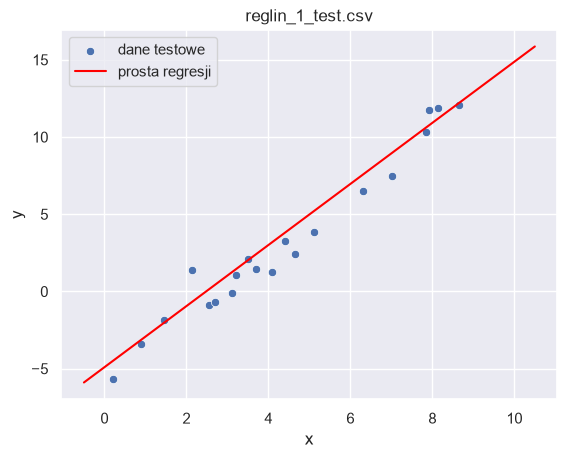

In [63]:
x_fit = np.linspace(-0.5, 10.5, 100)
y_fit = lr.coef_[0]*x_fit + lr.intercept_

sns.scatterplot(df_test, x='x', y='y', label='dane testowe')
sns.lineplot(x=x_fit, y=y_fit, color='red', label='prosta regresji')
plt.title('reglin_1_test.csv')
plt.show()

Komentarz

Na danych testowych wyniki sa troche gorsze niz na treningowych (RMSE 1.12 zamiast 0.91, R2 0.95 zamiast 0.97), ale roznica jest mala - model dobrze generalizuje, nie jest przeuczony.

# Cwiczenie 2 - trenowanie modelu regresji nieliniowej

In [64]:
from sklearn.preprocessing import PolynomialFeatures

## reglin_2.csv

In [65]:
df2 = pd.read_csv('reglin_2.csv')
df2_test = pd.read_csv('reglin_2_test.csv')
df2_test.info()
df2_test.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       20 non-null     float64
 1   y       20 non-null     float64
dtypes: float64(2)
memory usage: 452.0 bytes


,x,y
0,5.813768,6.360119
1,1.722501,-1.949663
2,4.007358,0.250559
3,7.809559,10.773168
4,6.317891,5.237792


Zwykla regresja liniowa

In [66]:
lr2a = LinearRegression()
lr2a.fit(df2[['x']], df2['y'])
yp2a = lr2a.predict(df2[['x']])

yp2a_test = lr2a.predict(df2_test[['x']])

print('RMSE (train) =', root_mean_squared_error(df2['y'], yp2a))
print('RMSE (test)  =', root_mean_squared_error(df2_test['y'], yp2a_test))
print('R2 (train)   =', r2_score(df2['y'], yp2a))
print('R2 (test)    =', r2_score(df2_test['y'], yp2a_test))

RMSE (train) = 2.8887345124583566
RMSE (test)  = 2.42111671551354
R2 (train)   = 0.8084065079290149
R2 (test)    = 0.8649645504521284


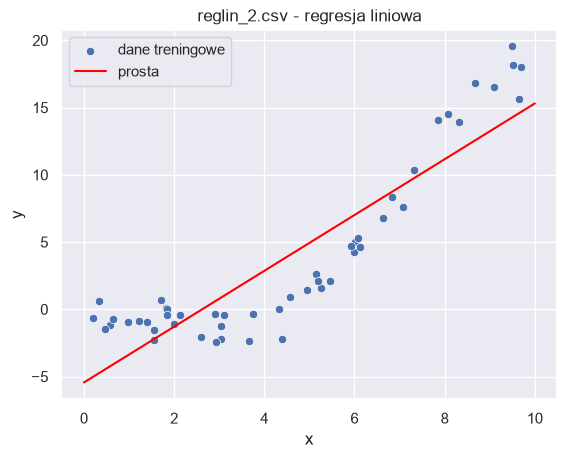

In [67]:
x_fit = np.linspace(0, 10, 200)
sns.scatterplot(df2, x='x', y='y', label='dane treningowe')
sns.lineplot(x=x_fit, y=lr2a.coef_[0]*x_fit + lr2a.intercept_, color='red', label='prosta')
plt.title('reglin_2.csv - regresja liniowa')
plt.show()

Generowanie cech (x^2) za pomoca PolynomialFeatures

In [68]:
pf2 = PolynomialFeatures(2, include_bias=False).set_output(transform='pandas')
X2 = pf2.fit_transform(df2[['x']])
X2_test = pf2.transform(df2_test[['x']])
X2.head()

,x,x^2
0,3.745401,14.028030
1,9.507143,90.385769
2,7.319939,53.581513
3,5.986585,35.839198
4,1.560186,2.434182


In [69]:
lr2b = LinearRegression()
lr2b.fit(X2, df2['y'])
yp2b_train = lr2b.predict(X2)
yp2b_test = lr2b.predict(X2_test)

print('wspolczynniki =', lr2b.coef_)
print('b =', lr2b.intercept_)
print('RMSE (train) =', root_mean_squared_error(df2['y'], yp2b_train))
print('RMSE (test)  =', root_mean_squared_error(df2_test['y'], yp2b_test))
print('R2 (train)   =', r2_score(df2['y'], yp2b_train))
print('R2 (test)    =', r2_score(df2_test['y'], yp2b_test))

wspolczynniki = [-1.34087741  0.35020357]
b = -0.03661753964315295
RMSE (train) = 1.2750533373573159
RMSE (test)  = 1.2884793347624404
R2 (train)   = 0.9626730764178592
R2 (test)    = 0.9617553001024589


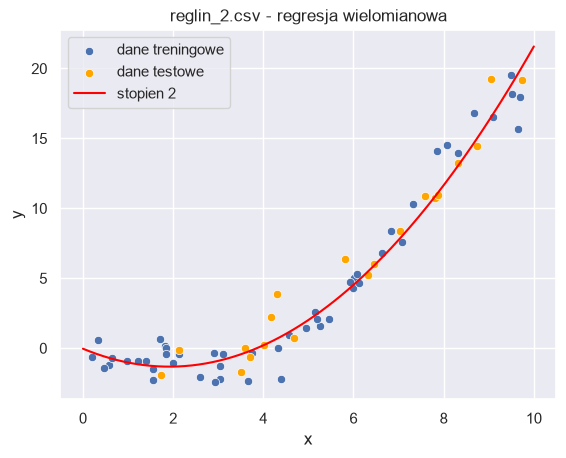

In [70]:
x_fit = pd.DataFrame({'x': np.linspace(0, 10, 200)})
y_fit = lr2b.predict(pf2.transform(x_fit))

sns.scatterplot(df2, x='x', y='y', label='dane treningowe')
sns.scatterplot(df2_test, x='x', y='y', label='dane testowe', color='orange')
sns.lineplot(x=x_fit['x'], y=y_fit, color='red', label='stopien 2')
plt.title('reglin_2.csv - regresja wielomianowa')
plt.show()

## reglin_3.csv

In [71]:
df3 = pd.read_csv('reglin_3.csv')
df3_test = pd.read_csv('reglin_3_test.csv')
df3_test.info()
df3_test.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       20 non-null     float64
 1   y       20 non-null     float64
dtypes: float64(2)
memory usage: 452.0 bytes


,x,y
0,10.282111,18.767247
1,3.499363,-1.078100
2,13.657689,18.938002
3,12.595867,21.611610
4,9.491453,18.004304


Zwykla regresja liniowa

In [72]:
lr3a = LinearRegression()
lr3a.fit(df3[['x']], df3['y'])
yp3a = lr3a.predict(df3[['x']])

yp3a_test = lr3a.predict(df3_test[['x']])

print('RMSE (train) =', root_mean_squared_error(df3['y'], yp3a))
print('RMSE (test)  =', root_mean_squared_error(df3_test['y'], yp3a_test))
print('R2 (train)   =', r2_score(df3['y'], yp3a))
print('R2 (test)    =', r2_score(df3_test['y'], yp3a_test))

RMSE (train) = 2.979890739088102
RMSE (test)  = 3.308306677354236
R2 (train)   = 0.8858908011607038
R2 (test)    = 0.8417880444602234


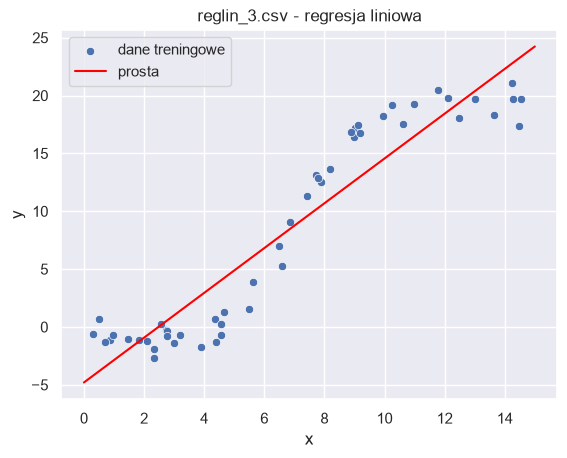

In [73]:
x_fit = np.linspace(0, 15, 200)
sns.scatterplot(df3, x='x', y='y', label='dane treningowe')
sns.lineplot(x=x_fit, y=lr3a.coef_[0]*x_fit + lr3a.intercept_, color='red', label='prosta')
plt.title('reglin_3.csv - regresja liniowa')
plt.show()

Generowanie cech (x^2 i x^3) za pomoca PolynomialFeatures

In [74]:
pf3 = PolynomialFeatures(3, include_bias=False).set_output(transform='pandas')
X3 = pf3.fit_transform(df3[['x']])
X3_test = pf3.transform(df3_test[['x']])
X3.head()

,x,x^2,x^3
0,5.618102,31.563068,177.324527
1,14.260715,203.367981,2900.172732
2,10.979909,120.558404,1323.720325
3,8.979877,80.638196,724.121100
4,2.340280,5.476909,12.817498


In [75]:
lr3b = LinearRegression()
lr3b.fit(X3, df3['y'])
yp3b_train = lr3b.predict(X3)
yp3b_test = lr3b.predict(X3_test)

print('wspolczynniki =', lr3b.coef_)
print('b =', lr3b.intercept_)
print('RMSE (train) =', root_mean_squared_error(df3['y'], yp3b_train))
print('RMSE (test)  =', root_mean_squared_error(df3_test['y'], yp3b_test))
print('R2 (train)   =', r2_score(df3['y'], yp3b_train))
print('R2 (test)    =', r2_score(df3_test['y'], yp3b_test))

wspolczynniki = [-3.33369335  0.92623845 -0.04260231]
b = 1.4277378916749814
RMSE (train) = 1.3531899541911063
RMSE (test)  = 0.7915885898996278
R2 (train)   = 0.9764691559679861
R2 (test)    = 0.9909421144951402


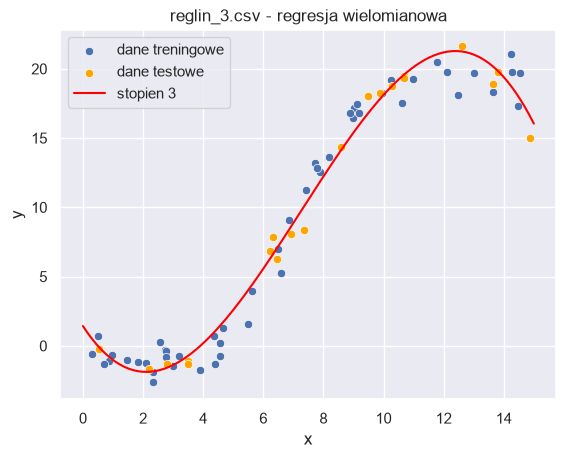

In [76]:
x_fit = pd.DataFrame({'x': np.linspace(0, 15, 200)})
y_fit = lr3b.predict(pf3.transform(x_fit))

sns.scatterplot(df3, x='x', y='y', label='dane treningowe')
sns.scatterplot(df3_test, x='x', y='y', label='dane testowe', color='orange')
sns.lineplot(x=x_fit['x'], y=y_fit, color='red', label='stopien 3')
plt.title('reglin_3.csv - regresja wielomianowa')
plt.show()

Komentarz

reglin_2 - prosta slabo pasuje (R2 0.81, na testowych 0.87), bo dane sa paraboliczne. Po dodaniu x^2 R2 rosnie do 0.96 i na testowych wychodzi prawie tak samo (RMSE 1.28 vs 1.29), wiec model jest dobry.

reglin_3 - prosta ma R2 0.89, a na testowych jeszcze gorzej (0.84). Z x^2 i x^3 R2 rosnie do 0.98 na treningowych i 0.99 na testowych - model dobrze lapie ksztalt "schodkow" i nie jest przeuczony.

# Cwiczenie 3 - trenowanie i ocena modeli klasyfikacji

## Generowanie danych

In [77]:
from sklearn.datasets import make_blobs

X, y = make_blobs(500, 2, centers=2, cluster_std=1.5, random_state=3)
blobs = pd.DataFrame({'x1': X[:, 0], 'x2': X[:, 1], 'y': y})
blobs.info()
blobs.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      500 non-null    float64
 1   x2      500 non-null    float64
 2   y       500 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 11.8 KB


,x1,x2,y
0,3.537324,3.429447,0
1,0.492405,4.542194,0
2,-3.055341,-2.149115,1
3,3.861309,2.354252,0
4,-3.558993,2.613905,1


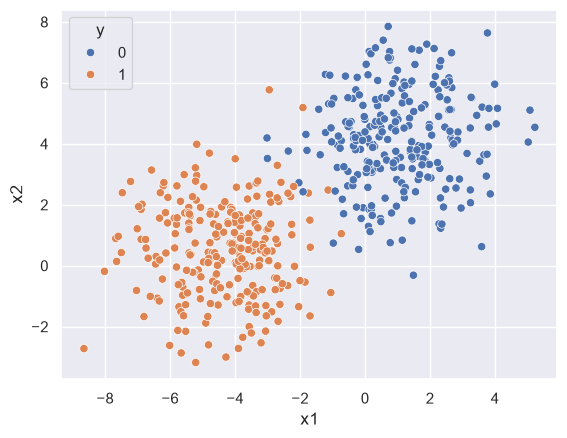

In [78]:
sns.scatterplot(blobs, x='x1', y='x2', hue='y')
plt.show()

## Statystyki opisowe i rozklady zmiennych

In [79]:
blobs.describe()

,x1,x2,y
count,500.000000,500.000000,500.000000
mean,-1.679497,2.331780,0.500000
std,3.077473,2.407106,0.500501
min,-8.647593,-3.176810,0.000000
25%,-4.178975,0.479570,0.000000
50%,-1.797774,2.252788,0.500000
75%,0.936733,4.192651,1.000000
max,5.233776,7.849338,1.000000


In [80]:
blobs['y'].value_counts()

y
0    250
1    250
Name: count, dtype: int64

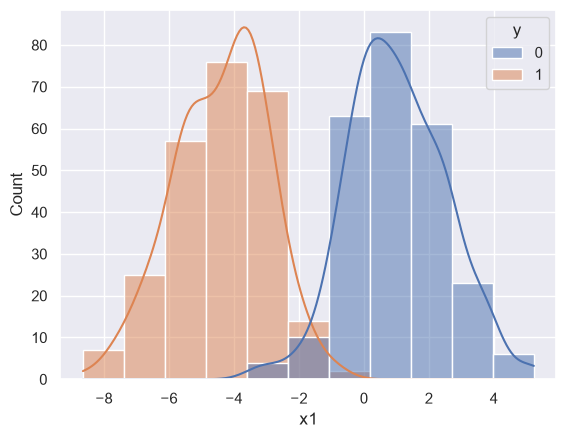

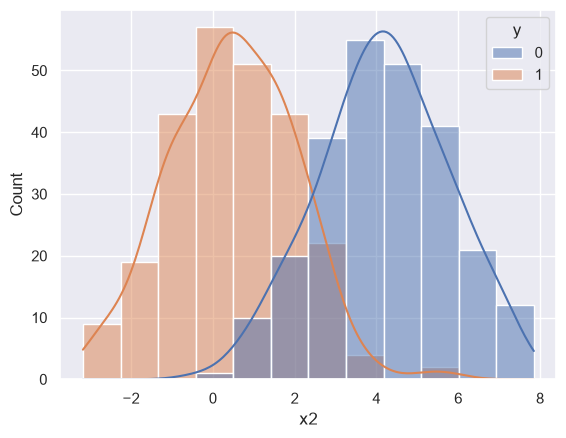

In [81]:
sns.histplot(blobs, x='x1', hue='y', kde=True)
plt.show()

sns.histplot(blobs, x='x2', hue='y', kde=True)
plt.show()

## Podzial 80:20 i standaryzacja

Najpierw dziele dane, a potem dopasowuje StandardScaler tylko na zbiorze treningowym - zbior testowy jest tylko transformowany (tak jak w skrypcie, rozdzial 8).

In [82]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(blobs[['x1', 'x2']], blobs['y'], test_size=0.2,
                                                    stratify=blobs['y'], random_state=42)

ssc = StandardScaler()
X_train = pd.DataFrame(ssc.fit_transform(X_train), columns=['x1', 'x2'])
X_test = pd.DataFrame(ssc.transform(X_test), columns=['x1', 'x2'])

print(X_train.shape, X_test.shape)
print(y_train.value_counts().to_dict(), y_test.value_counts().to_dict())
X_train.aggregate(['mean', 'std'])

(400, 2) (100, 2)
{1: 200, 0: 200} {1: 50, 0: 50}


,x1,x2
mean,8.104628e-17,-5.773160e-17
std,1.001252e+00,1.001252e+00


## Trenowanie modeli z roznymi hiperparametrami

In [83]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, \
    ConfusionMatrixDisplay, RocCurveDisplay

modele = {
    'GaussianNB': GaussianNB(),
    'SVC linear C=0.01': SVC(kernel='linear', C=0.01),
    'SVC linear C=10': SVC(kernel='linear', C=10),
    'SVC rbf C=1': SVC(kernel='rbf', C=1),
    'SVC rbf C=1000 gamma=10': SVC(kernel='rbf', C=1000, gamma=10),
}

for nazwa, model in modele.items():
    model.fit(X_train, y_train)

## Ocena modeli na zbiorze treningowym i testowym

In [84]:
wyniki = []
for nazwa, model in modele.items():
    for zbior, Xz, yz in [('train', X_train, y_train), ('test', X_test, y_test)]:
        yp = model.predict(Xz)
        wyniki.append({'model': nazwa, 'zbior': zbior,
                       'dokladnosc': accuracy_score(yz, yp),
                       'precyzja': precision_score(yz, yp),
                       'czulosc': recall_score(yz, yp),
                       'F1': f1_score(yz, yp),
                       'AUC': roc_auc_score(yz, model.decision_function(Xz) if hasattr(model, 'decision_function')
                                            else model.predict_proba(Xz)[:, 1])})

pd.DataFrame(wyniki).set_index(['model', 'zbior']).round(3)

dokladnosc  precyzja  czulosc     F1    AUC
model                   zbior                                             
GaussianNB              train       0.980     0.975    0.985  0.980  0.999
                        test        0.980     0.980    0.980  0.980  0.998
SVC linear C=0.01       train       0.982     0.975    0.990  0.983  0.999
                        test        0.980     0.980    0.980  0.980  0.996
SVC linear C=10         train       0.980     0.975    0.985  0.980  0.999
                        test        0.980     0.980    0.980  0.980  0.999
SVC rbf C=1             train       0.980     0.975    0.985  0.980  0.999
                        test        0.980     0.980    0.980  0.980  0.999
SVC rbf C=1000 gamma=10 train       1.000     1.000    1.000  1.000  1.000
                        test        0.950     0.959    0.940  0.949  0.980

## Macierze pomylek (zbior testowy)

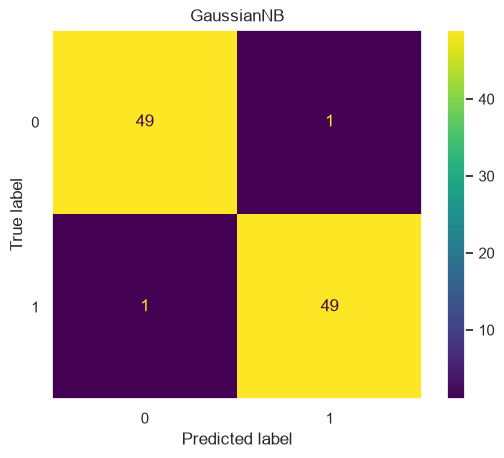

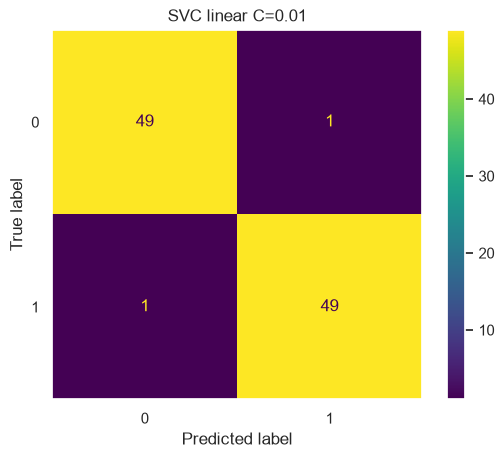

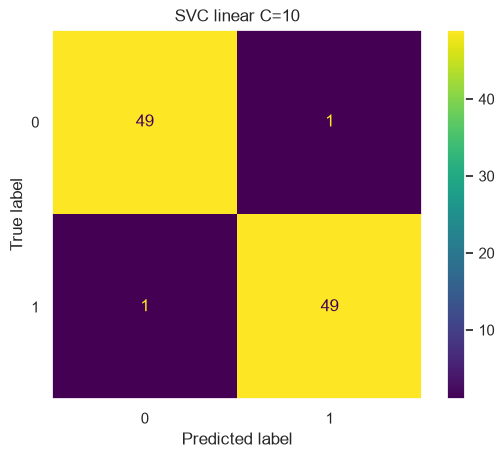

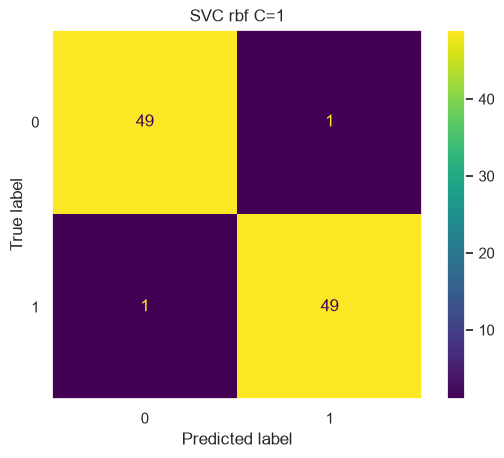

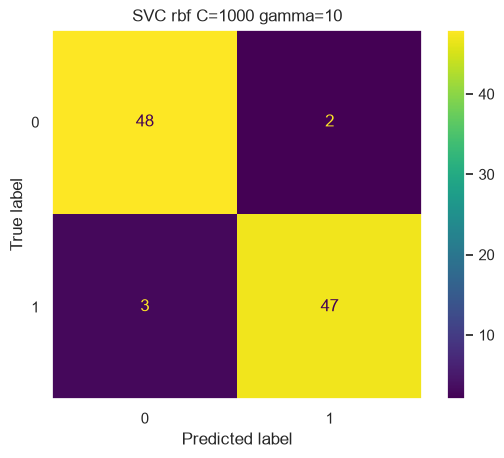

In [85]:
for nazwa, model in modele.items():
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
    plt.title(nazwa)
    plt.grid(False)
    plt.show()

## Krzywe ROC

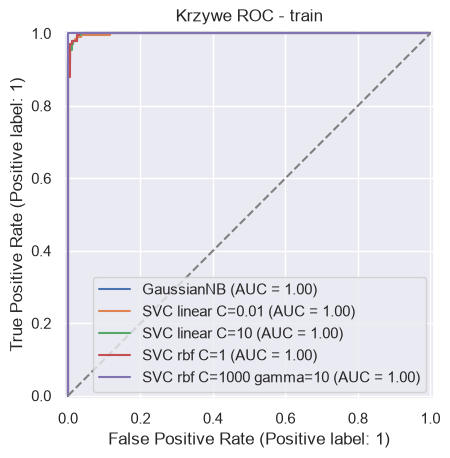

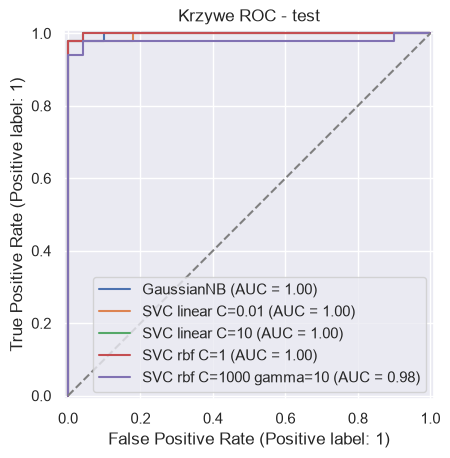

In [86]:
for zbior, Xz, yz in [('train', X_train, y_train), ('test', X_test, y_test)]:
    for nazwa, model in modele.items():
        RocCurveDisplay.from_estimator(model, Xz, yz, name=nazwa, ax=plt.gca())
    plt.gca().plot([0, 1], [0, 1], '--', c='gray')
    plt.title(f'Krzywe ROC - {zbior}')
    plt.show()

Komentarz

Klasy sa prawie rozdzielone, wiec wszystkie modele maja ok. 98% dokladnosci, a na testowych wyniki sa prawie takie same jak na treningowych - modele dobrze generalizuja. Jedynie SVC rbf z duzymi C=1000 i gamma=10 ma 100% na treningowych, ale na testowych spada do 95% - to przeuczenie, granica decyzyjna dopasowala sie do pojedynczych punktow.

# Cwiczenie 4 - klasyfikacja chorob serca (heart.csv)

## Eksploracyjna analiza danych

In [87]:
heart = pd.read_csv('heart.csv')
heart.info()
heart.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [88]:
heart.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [89]:
print(heart['HeartDisease'].value_counts())
print('duplikaty:', heart.duplicated().sum())

HeartDisease
1    508
0    410
Name: count, dtype: int64
duplikaty: 0


Rozklady zmiennych liczbowych z podzialem na klase

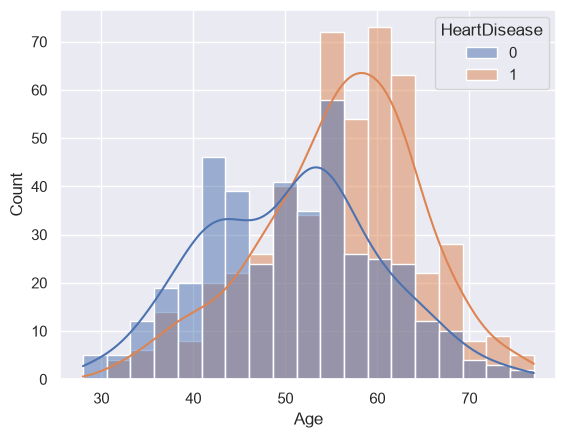

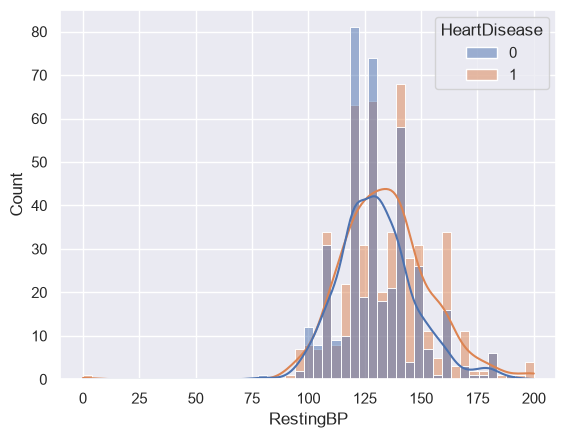

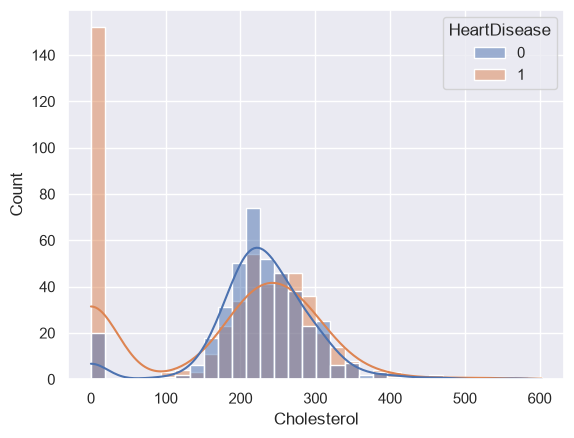

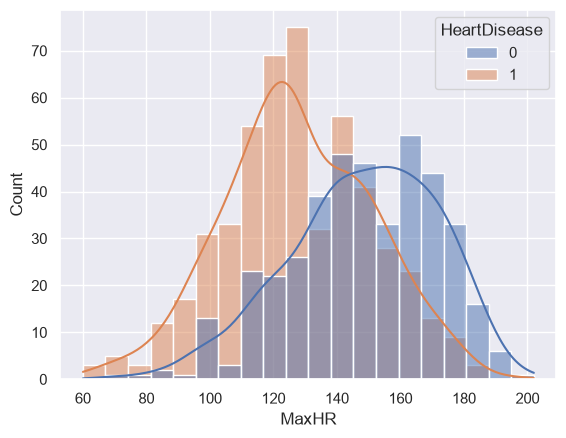

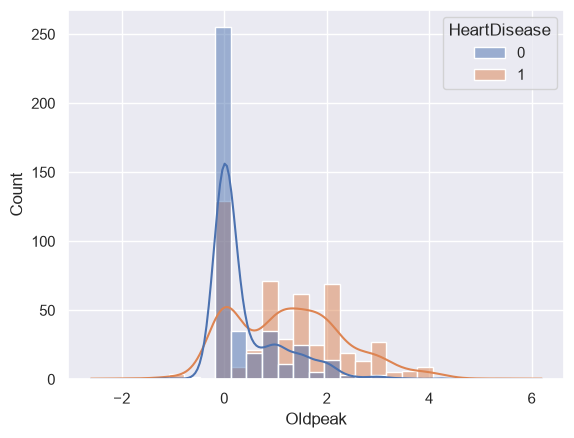

In [90]:
for kolumna in ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']:
    sns.histplot(heart, x=kolumna, hue='HeartDisease', kde=True)
    plt.show()

Zmienne kategoryczne a zmienna celu

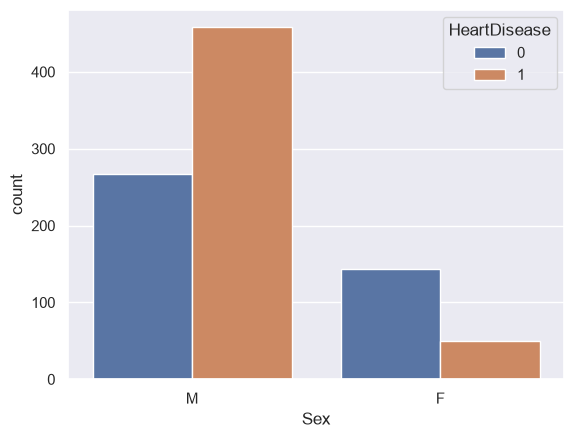

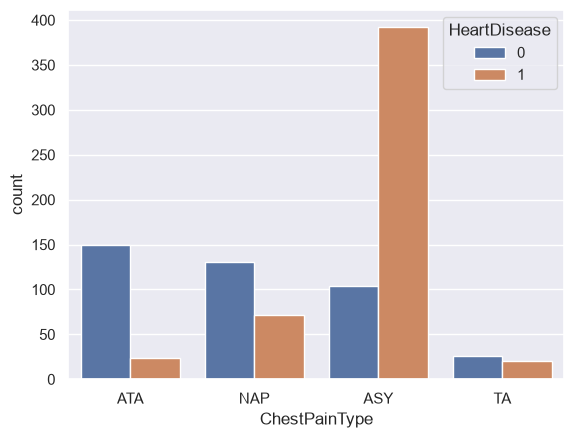

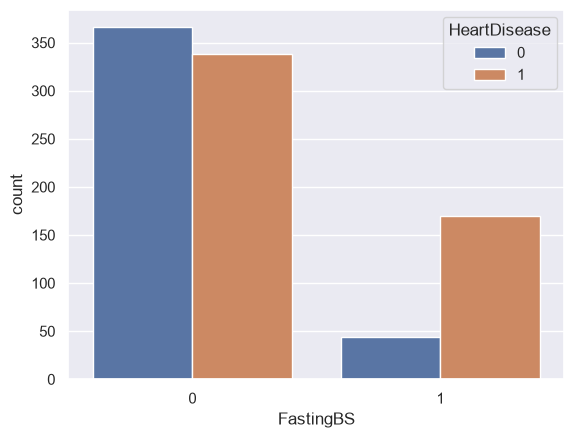

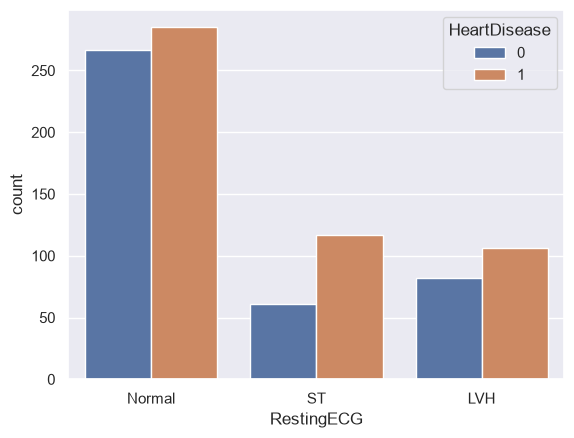

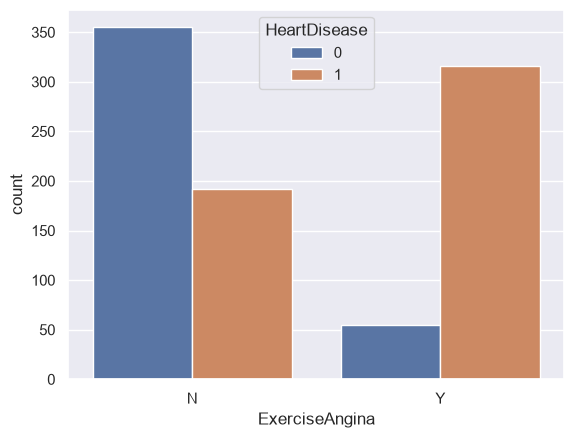

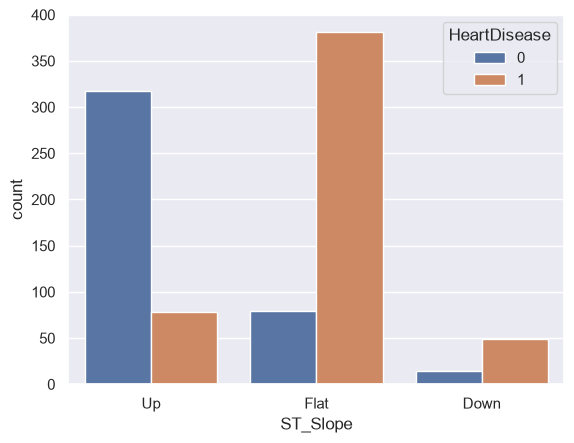

In [91]:
for kolumna in ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']:
    sns.countplot(heart, x=kolumna, hue='HeartDisease')
    plt.show()

In [92]:
for kolumna in ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']:
    print(heart.groupby(kolumna)['HeartDisease'].mean().round(2).to_dict())

{'F': 0.26, 'M': 0.63}
{'ASY': 0.79, 'ATA': 0.14, 'NAP': 0.35, 'TA': 0.43}
{0: 0.48, 1: 0.79}
{'LVH': 0.56, 'Normal': 0.52, 'ST': 0.66}
{'N': 0.35, 'Y': 0.85}
{'Down': 0.78, 'Flat': 0.83, 'Up': 0.2}


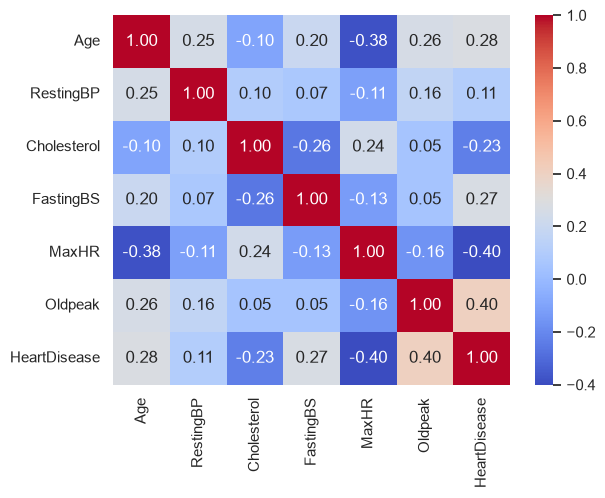

In [93]:
sns.heatmap(heart.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

## a) Usuniecie nieistotnych cech

Nie ma kolumn typu ID ani duplikatow. RestingECG prawie nie rozroznia klas (udzial chorych 0.52-0.66 dla kazdej wartosci), wiec ja usuwam.

In [94]:
df_h = heart.drop(columns=['RestingECG'])

## b) Brakujace wartosci

W zbiorze nie ma NaN, ale Cholesterol = 0 i RestingBP = 0 to w rzeczywistosci braki. Zamieniam je na NaN i uzupelniam mediana. Dodatkowo zapisuje informacje o braku cholesterolu, bo wiekszosc takich pacjentow jest chora.

In [95]:
print((df_h[['RestingBP', 'Cholesterol']] == 0).sum())
print(df_h[df_h['Cholesterol'] == 0]['HeartDisease'].value_counts())

RestingBP        1
Cholesterol    172
dtype: int64
HeartDisease
1    152
0     20
Name: count, dtype: int64


In [96]:
df_h['Cholesterol_brak'] = (df_h['Cholesterol'] == 0).astype(int)
df_h[['RestingBP', 'Cholesterol']] = df_h[['RestingBP', 'Cholesterol']].replace(0, np.nan)

for kolumna in ['RestingBP', 'Cholesterol']:
    df_h[kolumna] = df_h[kolumna].fillna(df_h[kolumna].median())

df_h.isna().sum().sum()

np.int64(0)

## c) Wartosci odstajace

Regula IQR - wartosci dalej niz 1.5 x IQR od kwartyli przycinam do granicy (zamiast usuwac wiersze).

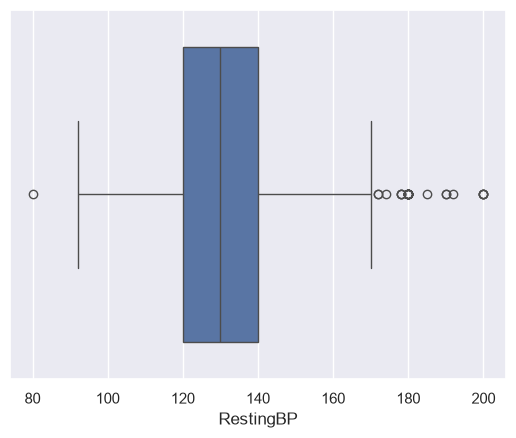

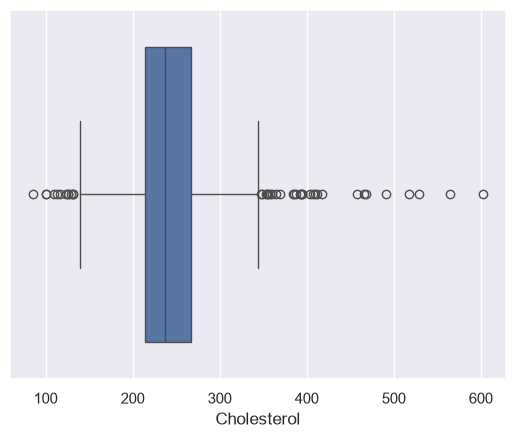

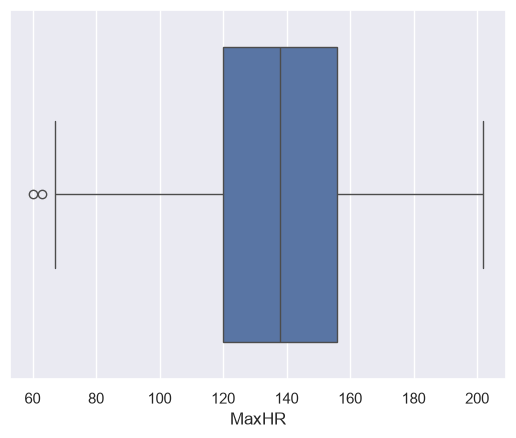

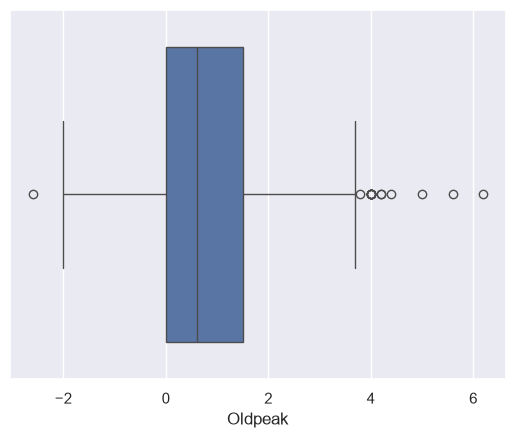

In [97]:
def iqr_granice(s):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


for kolumna in ['RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']:
    sns.boxplot(df_h, x=kolumna)
    plt.show()

In [98]:
for kolumna in ['RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']:
    dol, gora = iqr_granice(df_h[kolumna])
    print(kolumna, '- odstajace:', ((df_h[kolumna] < dol) | (df_h[kolumna] > gora)).sum())
    df_h[kolumna] = df_h[kolumna].clip(dol, gora)

RestingBP - odstajace: 27
Cholesterol - odstajace: 41
MaxHR - odstajace: 2
Oldpeak - odstajace: 16


## e) Kodowanie zmiennych kategorycznych

In [99]:
df_h['Sex'] = (df_h['Sex'] == 'M').astype(int)
df_h['ExerciseAngina'] = (df_h['ExerciseAngina'] == 'Y').astype(int)
df_h = pd.get_dummies(df_h, columns=['ChestPainType', 'ST_Slope'], dtype=int)
df_h.info()
df_h.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                918 non-null    int64  
 1   Sex                918 non-null    int64  
 2   RestingBP          918 non-null    float64
 3   Cholesterol        918 non-null    float64
 4   FastingBS          918 non-null    int64  
 5   MaxHR              918 non-null    int64  
 6   ExerciseAngina     918 non-null    int64  
 7   Oldpeak            918 non-null    float64
 8   HeartDisease       918 non-null    int64  
 9   Cholesterol_brak   918 non-null    int64  
 10  ChestPainType_ASY  918 non-null    int64  
 11  ChestPainType_ATA  918 non-null    int64  
 12  ChestPainType_NAP  918 non-null    int64  
 13  ChestPainType_TA   918 non-null    int64  
 14  ST_Slope_Down      918 non-null    int64  
 15  ST_Slope_Flat      918 non-null    int64  
 16  ST_Slope_Up        918 non

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,Cholesterol_brak,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,1,140.0,289.0,0,172,0,0.0,0,0,0,1,0,0,0,0,1
1,49,0,160.0,180.0,0,156,0,1.0,1,0,0,0,1,0,0,1,0
2,37,1,130.0,283.0,0,98,0,0.0,0,0,0,1,0,0,0,0,1
3,48,0,138.0,214.0,0,108,1,1.5,1,0,1,0,0,0,0,1,0
4,54,1,150.0,195.0,0,122,0,0.0,0,0,0,0,1,0,0,0,1


## f) Podzial na dane treningowe i testowe

Podzial 80:20 z zachowaniem proporcji klas.

In [100]:
X_h = df_h.drop(columns=['HeartDisease'])
y_h = df_h['HeartDisease']

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(X_h, y_h, test_size=0.2,
                                                            stratify=y_h, random_state=42)
print(X_h_train.shape, X_h_test.shape)

(734, 16) (184, 16)


## d) Skalowanie zmiennych ciaglych

Robione po podziale - StandardScaler uczony tylko na zbiorze treningowym.

In [101]:
ciagle = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

X_h_train = X_h_train.copy()
X_h_test = X_h_test.copy()
ssc_h = StandardScaler()
X_h_train[ciagle] = ssc_h.fit_transform(X_h_train[ciagle])
X_h_test[ciagle] = ssc_h.transform(X_h_test[ciagle])
X_h_train.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,Cholesterol_brak,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
485,0.970012,1,0.383646,-0.567514,1,-0.325432,1,0.333747,0,0,1,0,0,0,1,0
486,0.122028,1,-1.321927,-0.633632,1,1.691632,0,-0.445018,0,0,1,0,0,0,0,1
117,0.546020,0,-0.145670,2.099252,1,-0.247852,1,0.625784,0,1,0,0,0,0,1,0
361,-0.725956,1,1.618715,-0.126726,0,-0.480590,1,-0.834400,1,1,0,0,0,0,1,0
296,-0.407962,1,0.736523,-0.126726,1,0.101255,1,-0.152981,1,1,0,0,0,0,1,0


## Trenowanie i ocena modeli (najwazniejsza jest czulosc)

In [102]:
modele_h = {
    'GaussianNB': GaussianNB(),
    'SVC linear': SVC(kernel='linear'),
    'SVC rbf C=0.1': SVC(kernel='rbf', C=0.1),
    'SVC rbf C=1': SVC(kernel='rbf', C=1),
    'SVC rbf C=10': SVC(kernel='rbf', C=10),
}

wyniki_h = []
for nazwa, model in modele_h.items():
    model.fit(X_h_train, y_h_train)
    for zbior, Xz, yz in [('train', X_h_train, y_h_train), ('test', X_h_test, y_h_test)]:
        yp = model.predict(Xz)
        wyniki_h.append({'model': nazwa, 'zbior': zbior,
                         'dokladnosc': accuracy_score(yz, yp),
                         'precyzja': precision_score(yz, yp),
                         'czulosc': recall_score(yz, yp),
                         'F1': f1_score(yz, yp)})

pd.DataFrame(wyniki_h).set_index(['model', 'zbior']).round(3)

dokladnosc  precyzja  czulosc     F1
model         zbior                                      
GaussianNB    train       0.850     0.865    0.865  0.865
              test        0.864     0.874    0.882  0.878
SVC linear    train       0.869     0.866    0.904  0.884
              test        0.875     0.869    0.912  0.890
SVC rbf C=0.1 train       0.866     0.850    0.921  0.884
              test        0.870     0.868    0.902  0.885
SVC rbf C=1   train       0.899     0.888    0.936  0.911
              test        0.897     0.895    0.922  0.908
SVC rbf C=10  train       0.952     0.956    0.958  0.957
              test        0.875     0.891    0.882  0.887

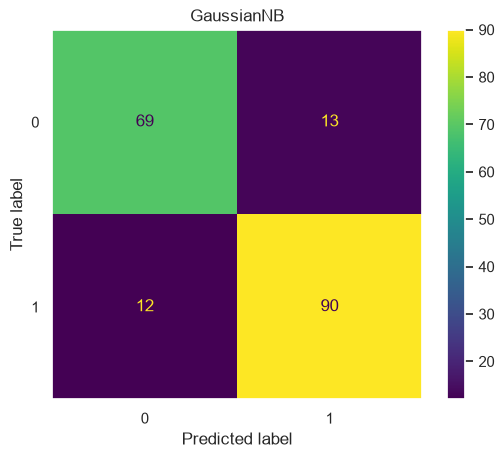

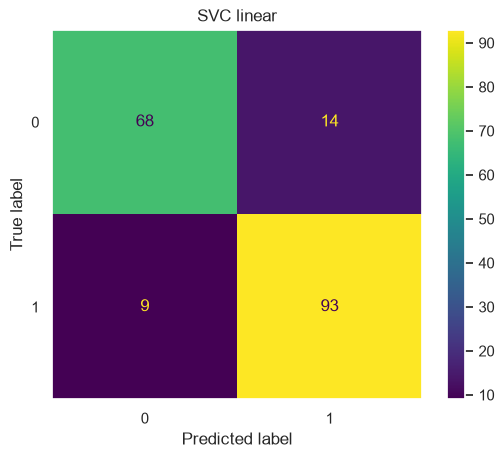

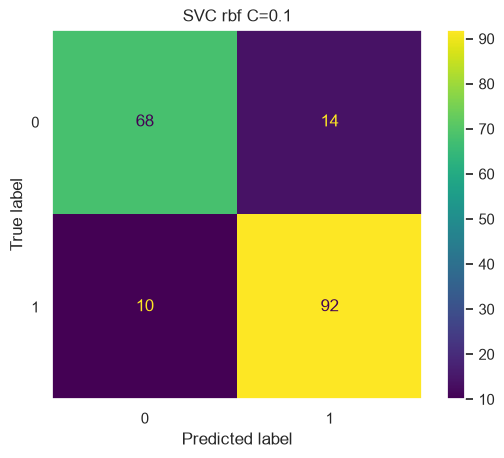

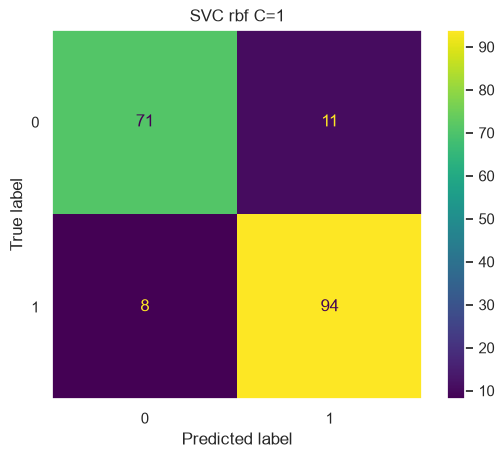

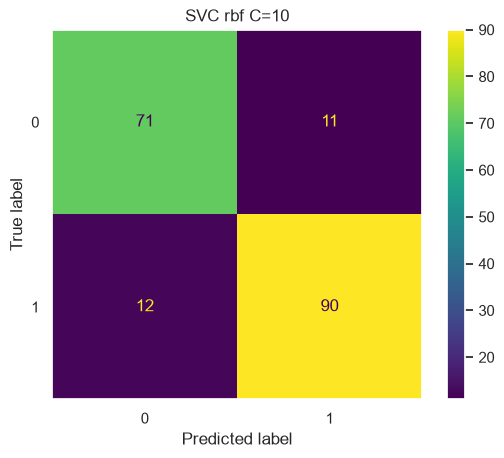

In [103]:
for nazwa, model in modele_h.items():
    ConfusionMatrixDisplay.from_estimator(model, X_h_test, y_h_test)
    plt.title(nazwa)
    plt.grid(False)
    plt.show()

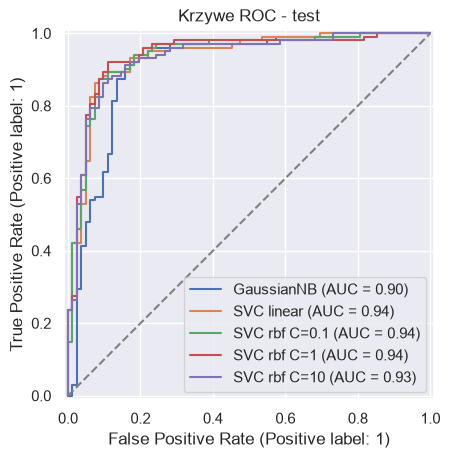

In [104]:
for nazwa, model in modele_h.items():
    RocCurveDisplay.from_estimator(model, X_h_test, y_h_test, name=nazwa, ax=plt.gca())
plt.gca().plot([0, 1], [0, 1], '--', c='gray')
plt.title('Krzywe ROC - test')
plt.show()

## Zwiekszenie czulosci - obnizenie progu

Domyslnie model mowi "chory", gdy prawdopodobienstwo >= 0.5. Obnizajac prog lapiemy wiecej chorych kosztem wiekszej liczby falszywych alarmow.

In [105]:
svc_p = SVC(kernel='rbf', C=1, probability=True, random_state=0)
svc_p.fit(X_h_train, y_h_train)
prob = svc_p.predict_proba(X_h_test)[:, 1]

for prog in [0.5, 0.4, 0.3, 0.2]:
    yp = (prob >= prog).astype(int)
    print('prog', prog, '- czulosc =', round(recall_score(y_h_test, yp), 3),
          'precyzja =', round(precision_score(y_h_test, yp), 3),
          'dokladnosc =', round(accuracy_score(y_h_test, yp), 3))

prog 0.5 - czulosc = 0.922 precyzja = 0.895 dokladnosc = 0.897
prog 0.4 - czulosc = 0.922 precyzja = 0.855 dokladnosc = 0.87
prog 0.3 - czulosc = 0.971 precyzja = 0.839 dokladnosc = 0.88
prog 0.2 - czulosc = 0.98 precyzja = 0.806 dokladnosc = 0.859


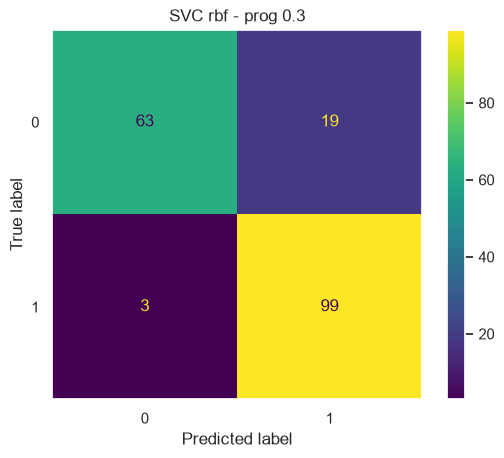

In [106]:
ConfusionMatrixDisplay.from_predictions(y_h_test, (prob >= 0.3).astype(int))
plt.title('SVC rbf - prog 0.3')
plt.grid(False)
plt.show()

Podsumowanie

Najwazniejsze cechy to ST_Slope, ChestPainType, ExerciseAngina, Oldpeak i MaxHR. Cholesterol = 0 to braki danych, a nie prawdziwa wartosc - i co ciekawe prawie wszyscy z brakiem sa chorzy. Najlepszy byl SVC z jadrem rbf (C=1): ok. 90% dokladnosci i 92% czulosci na testowych, bez przeuczenia. SVC z C=10 jest przeuczony (95% na treningowych, 87.5% na testowych). Poniewaz najwazniejsza jest czulosc, obnizylem prog do 0.3 - czulosc rosnie do 97% (pominieci tylko 3 chorzy na 102), a dokladnosc spada tylko z 90% do 88%.